c:\User\document\anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\User\document\anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py:110: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] 指定されたファイルが見つかりません。
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\User\document\anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py", line 199, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\User\document\anaconda\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File 

Saved clustering results to: clustering_result.csv


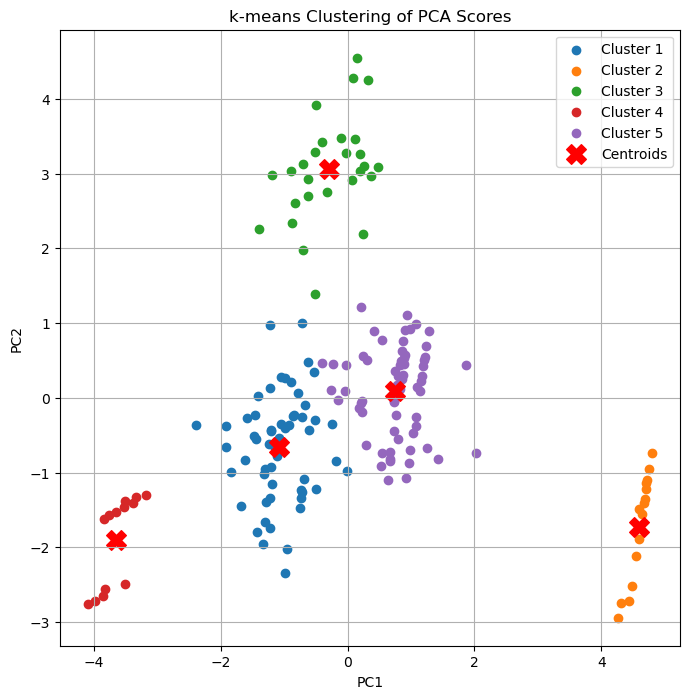

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# PCAの結果ファイルを読み込む
# 既に標準化後の PCA スコアがある場合はそちらを優先
# ない場合は古い 2D 出力も読み込めるようにする
try:
    data = pd.read_csv("pca_scores_standardized.csv")
except FileNotFoundError:
    data = pd.read_csv("pca_results_2D.csv")

# 2次元データの抽出
X = data[["PC1", "PC2"]].values

# KMeans クラスタリングの実行
num_clusters = 5
kmeans = KMeans(n_clusters=num_clusters, random_state=42)
clusters = kmeans.fit_predict(X)

data["Cluster"] = clusters

# 結果をCSVに保存
output_path = "clustering_result.csv"
data.to_csv(output_path, index=False)
print(f"Saved clustering results to: {output_path}")

# クラスタごとの散布図を描画
plt.figure(figsize=(8, 8))
for cluster in range(num_clusters):
    cluster_data = data[data["Cluster"] == cluster]
    plt.scatter(cluster_data["PC1"], cluster_data["PC2"], label=f"Cluster {cluster + 1}")

centroids = kmeans.cluster_centers_
plt.scatter(centroids[:, 0], centroids[:, 1], marker='X', s=200, c='red', label='Centroids')

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("k-means Clustering of PCA Scores")
plt.legend()
plt.grid(True)
plt.show()